# Perbandingan hasil eksperimen

Notebook ini menyusun tabel dan lima figur dari checkpoint terpilih dan hasil evaluasi yang sudah tersimpan. Semua baris memakai split Fashion-MNIST yang sama dengan seed 42. FID test memakai 2.048 citra asli dan 2.048 citra sintetis per model.

In [1]:
from pathlib import Path
import json
import shutil

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
METRICS = ROOT / "results/metrics"
OUT = ROOT / "results/final"
FIGURES = OUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
BENCH = json.loads((OUT / "benchmark.json").read_text(encoding="utf-8"))
VISUALS = np.load(OUT / "visual_data.npz")
AE_DIR = METRICS / "custom_ae_vae"

MODELS = {
    "Vanilla AE": ("vanilla_ae", "custom_ae_vae", "64"),
    "Sparse AE": ("sparse_ae", "custom_ae_vae", "64"),
    "VAE": ("vae", "custom_ae_vae", "64"),
    "Vanilla GAN": ("vanilla_gan", "custom_vanilla_gan_v2", "100"),
    "DCGAN": ("dcgan", "custom_dcgan_v2", "100"),
    "DDPM": ("ddpm", "custom_ddpm", "1 x 28 x 28"),
}
HISTORIES = {
    name: pd.read_csv(METRICS / directory / f"{slug}_history.csv")
    for name, (slug, directory, _) in MODELS.items()
}


## 1. Tabel evaluasi

MSE, PSNR, dan SSIM rekonstruksi dihitung pada 7.000 gambar test. File `validation.csv` menunjukkan skor yang dipakai untuk memilih checkpoint. Waktu epoch AE, VAE, dan DDPM berasal dari benchmark terpisah. Waktu epoch GAN berasal dari rerata 50 epoch run v2.

In [2]:
recon = pd.read_csv(AE_DIR / "test_reconstruction_metrics.csv", index_col=0)
rows = []
val_rows = []
for name, (slug, directory, latent) in MODELS.items():
    history = HISTORIES[name]
    row = {"Model": name, "Laten / derau": latent, "Epoch dilatih": int(history["epoch"].max())}
    if name in recon.index:
        row["Epoch terpilih"] = int(recon.loc[name, "Epoch"])
        row["MSE"] = recon.loc[name, "MSE (piksel^2)"]
        row["PSNR (dB)"] = recon.loc[name, "PSNR (dB)"]
        row["SSIM"] = recon.loc[name, "SSIM"]
        row["Rekonstruksi (ms/64)"] = BENCH["reconstruction_ms_64"][slug]

    if name in ("VAE", "Vanilla GAN", "DCGAN", "DDPM"):
        file = "vae_generative_metrics.csv" if name == "VAE" else f"{slug}_eval.csv"
        gen = pd.read_csv(METRICS / directory / file).iloc[0]
        row["FID test (N=2048)"] = gen["FID Test (N=2048)"]
        row["Generasi (ms/64)"] = gen["Latensi Batch 64 (ms)"]
        if "Epoch" in gen.index:
            row["Epoch terpilih"] = int(gen["Epoch"])

    if "train_seconds" in history:
        row["Detik/epoch"] = history["train_seconds"].mean()
        row["Sumber waktu"] = "Rerata 50 epoch run v2"
    else:
        row["Detik/epoch"] = BENCH["epoch_seconds"][slug]
        row["Sumber waktu"] = "Benchmark 1 epoch terpisah"

    if "val_mse" in history:
        column = "val_mse"
        row["Catatan training"] = f"Loss train awal/akhir {history.train_loss.iloc[0]:.4g}/{history.train_loss.iloc[-1]:.4g}"
    elif "d_loss" in history:
        column = "val_cnn_fid"
        row["Catatan training"] = f"Rentang loss G {history.g_loss.min():.4g}–{history.g_loss.max():.4g}, D {history.d_loss.min():.4g}–{history.d_loss.max():.4g}"
    else:
        column = "val_cnn_fid"
        row["Catatan training"] = f"MSE derau awal/akhir {history.train_mse.iloc[0]:.4g}/{history.train_mse.iloc[-1]:.4g}"

    candidates = history.dropna(subset=[column])
    assert np.isfinite(candidates[column]).all() and (candidates[column] >= 0).all()
    assert int(candidates.loc[candidates[column].idxmin(), "epoch"]) == row["Epoch terpilih"]
    for epoch, score in zip(candidates["epoch"], candidates[column]):
        val_rows.append({"Model": name, "Epoch": int(epoch), "Metrik validasi": column,
                         "Skor": score, "Terpilih": epoch == row["Epoch terpilih"]})
    rows.append(row)

comparison = pd.DataFrame(rows).reindex(columns=[
    "Model", "Laten / derau", "Epoch terpilih", "Epoch dilatih", "Detik/epoch",
    "Sumber waktu", "Rekonstruksi (ms/64)", "Generasi (ms/64)", "MSE",
    "PSNR (dB)", "SSIM", "FID test (N=2048)", "Catatan training",
])
comparison.to_csv(OUT / "comparison.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(val_rows).to_csv(OUT / "validation.csv", index=False, encoding="utf-8-sig")
display(comparison.round(6).fillna("N/A"))


         Model  ...                            Catatan training
0   Vanilla AE  ...       Loss train awal/akhir 0.03484/0.00769
1    Sparse AE  ...       Loss train awal/akhir 0.0355/0.008366
2          VAE  ...             Loss train awal/akhir 300.5/241
3  Vanilla GAN  ...  Rentang loss G 0.9977–4.48, D 0.2974–1.234
4        DCGAN  ...   Rentang loss G 1.332–2.92, D 0.2364–1.075
5         DDPM  ...         MSE derau awal/akhir 0.2557/0.08399

[6 rows x 13 columns]


## 2. Figur komparatif

Figur 4 memakai citra kelas T-shirt/top dan Ankle boot untuk AE dan VAE. Endpoint GAN dipilih berdasarkan prediksi classifier MLP pada sampel generator. Figur 5 menampilkan enam frame dari trajektori reverse DDPM yang sama.

Catatan metode, sumber angka, dan panduan memperbarui PDF terdapat di `results/final/README.md`.

Figur 1–5 tersimpan di C:\Users\COLLAPSION\Documents\Bina Nusantara\Semester 5\Deep Learning\assigment\Tugas takehome AE_&_GAN\results\final\figures


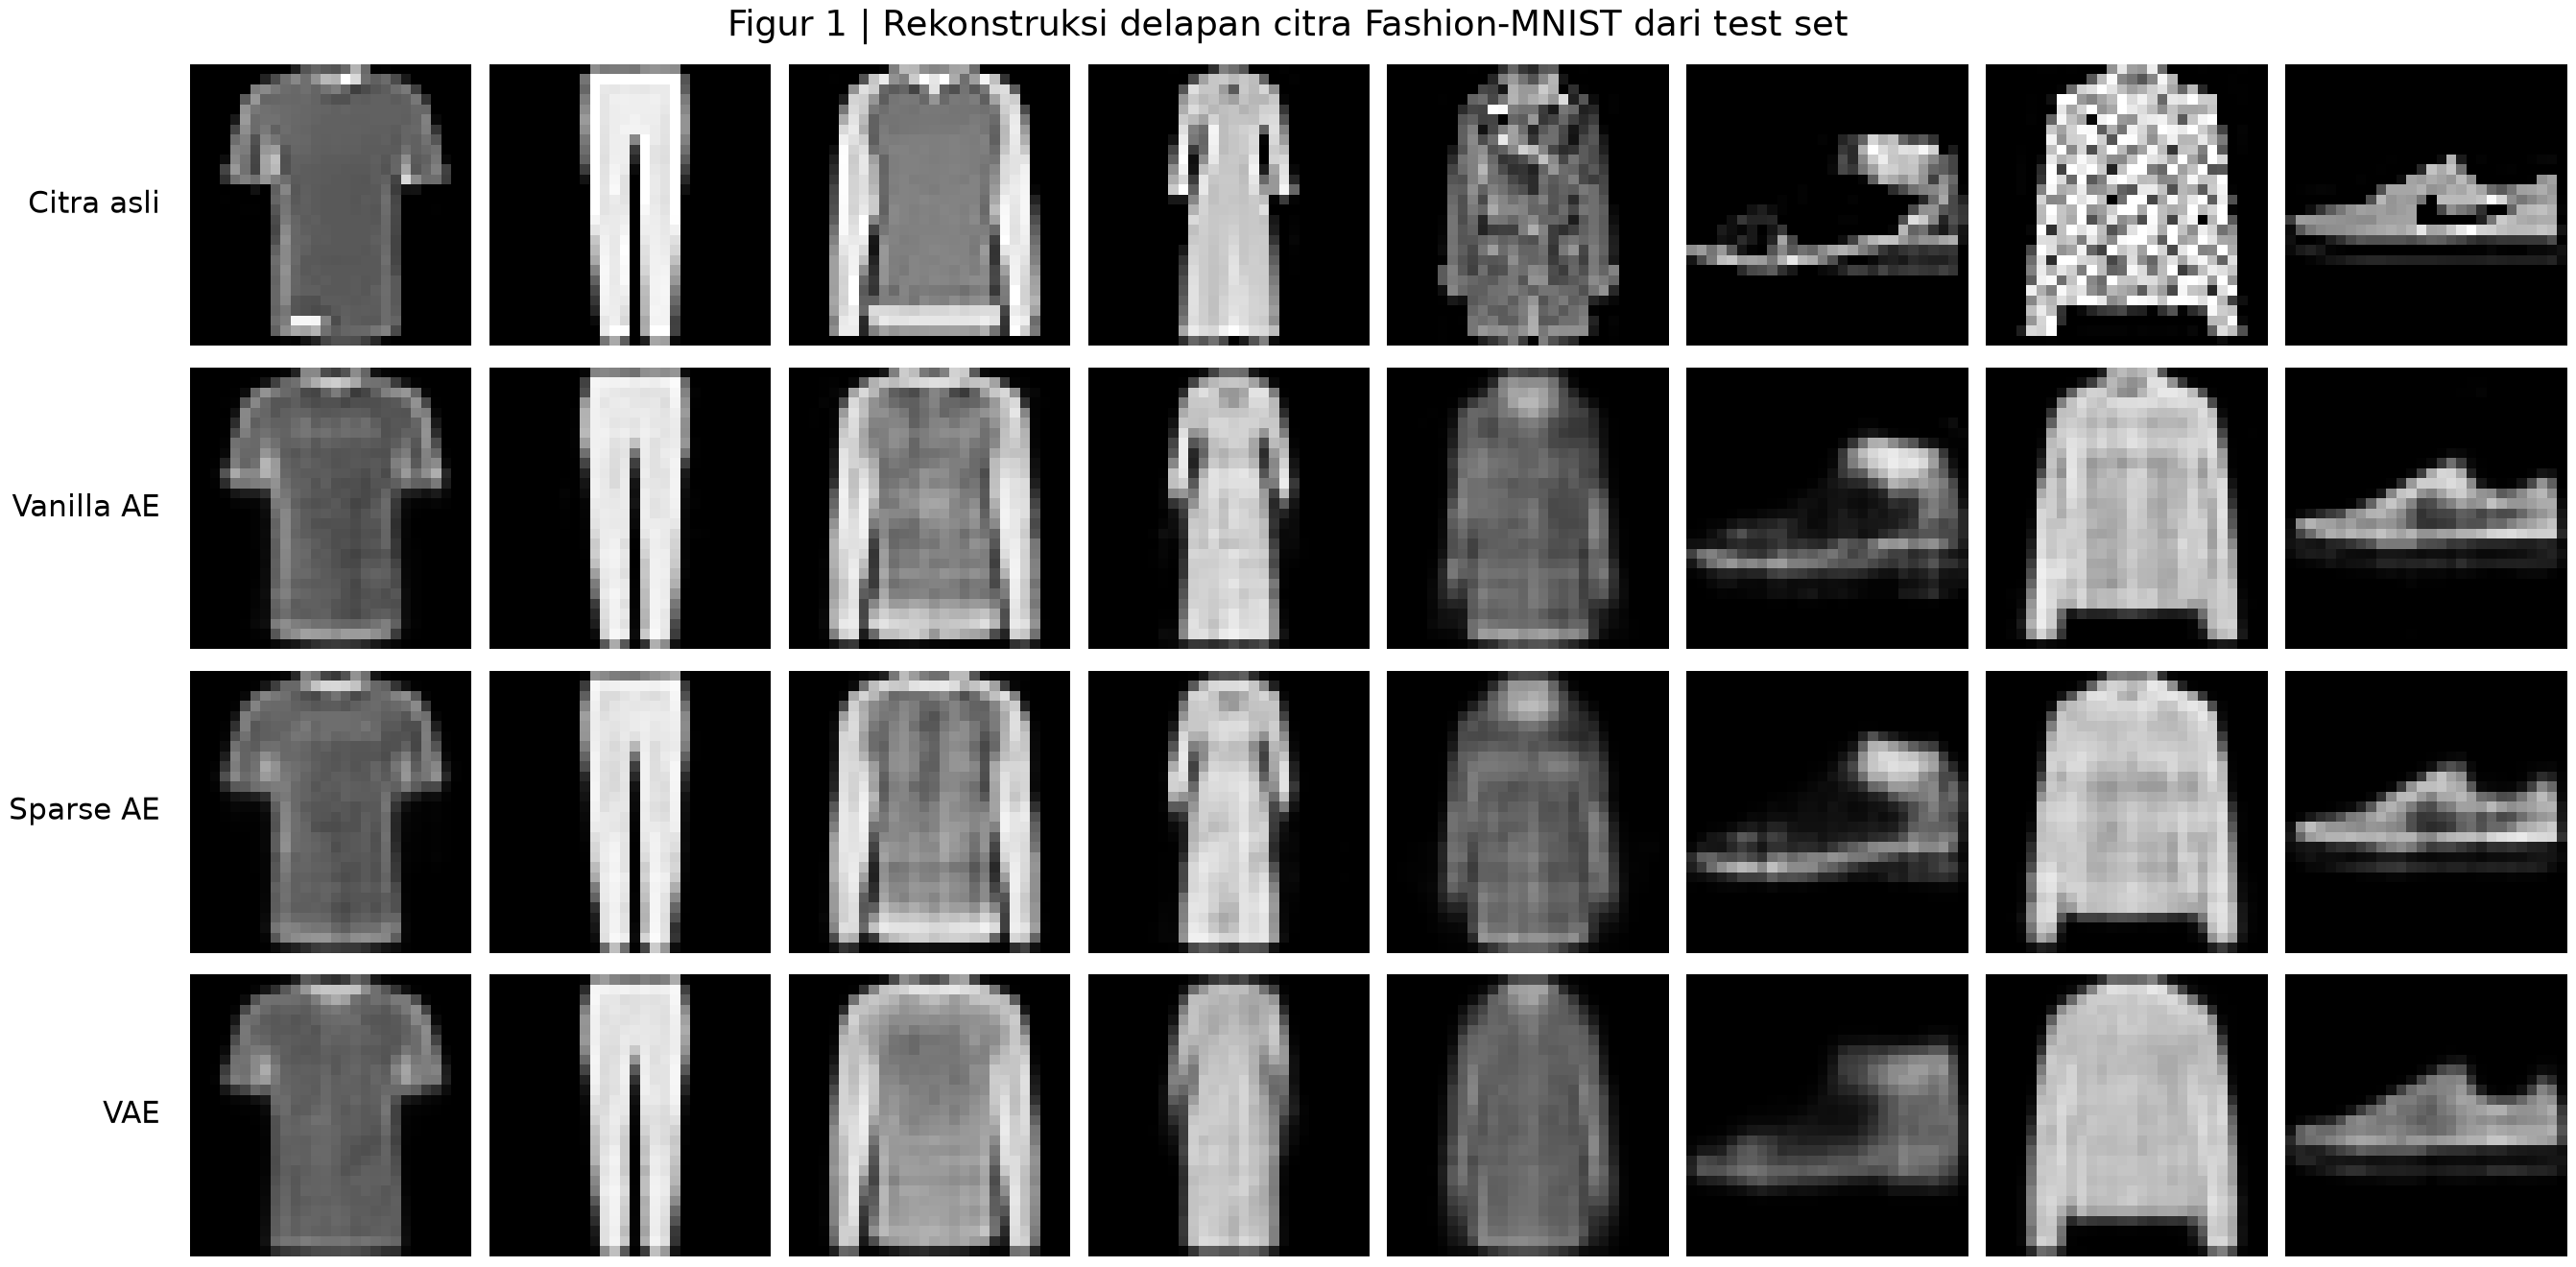

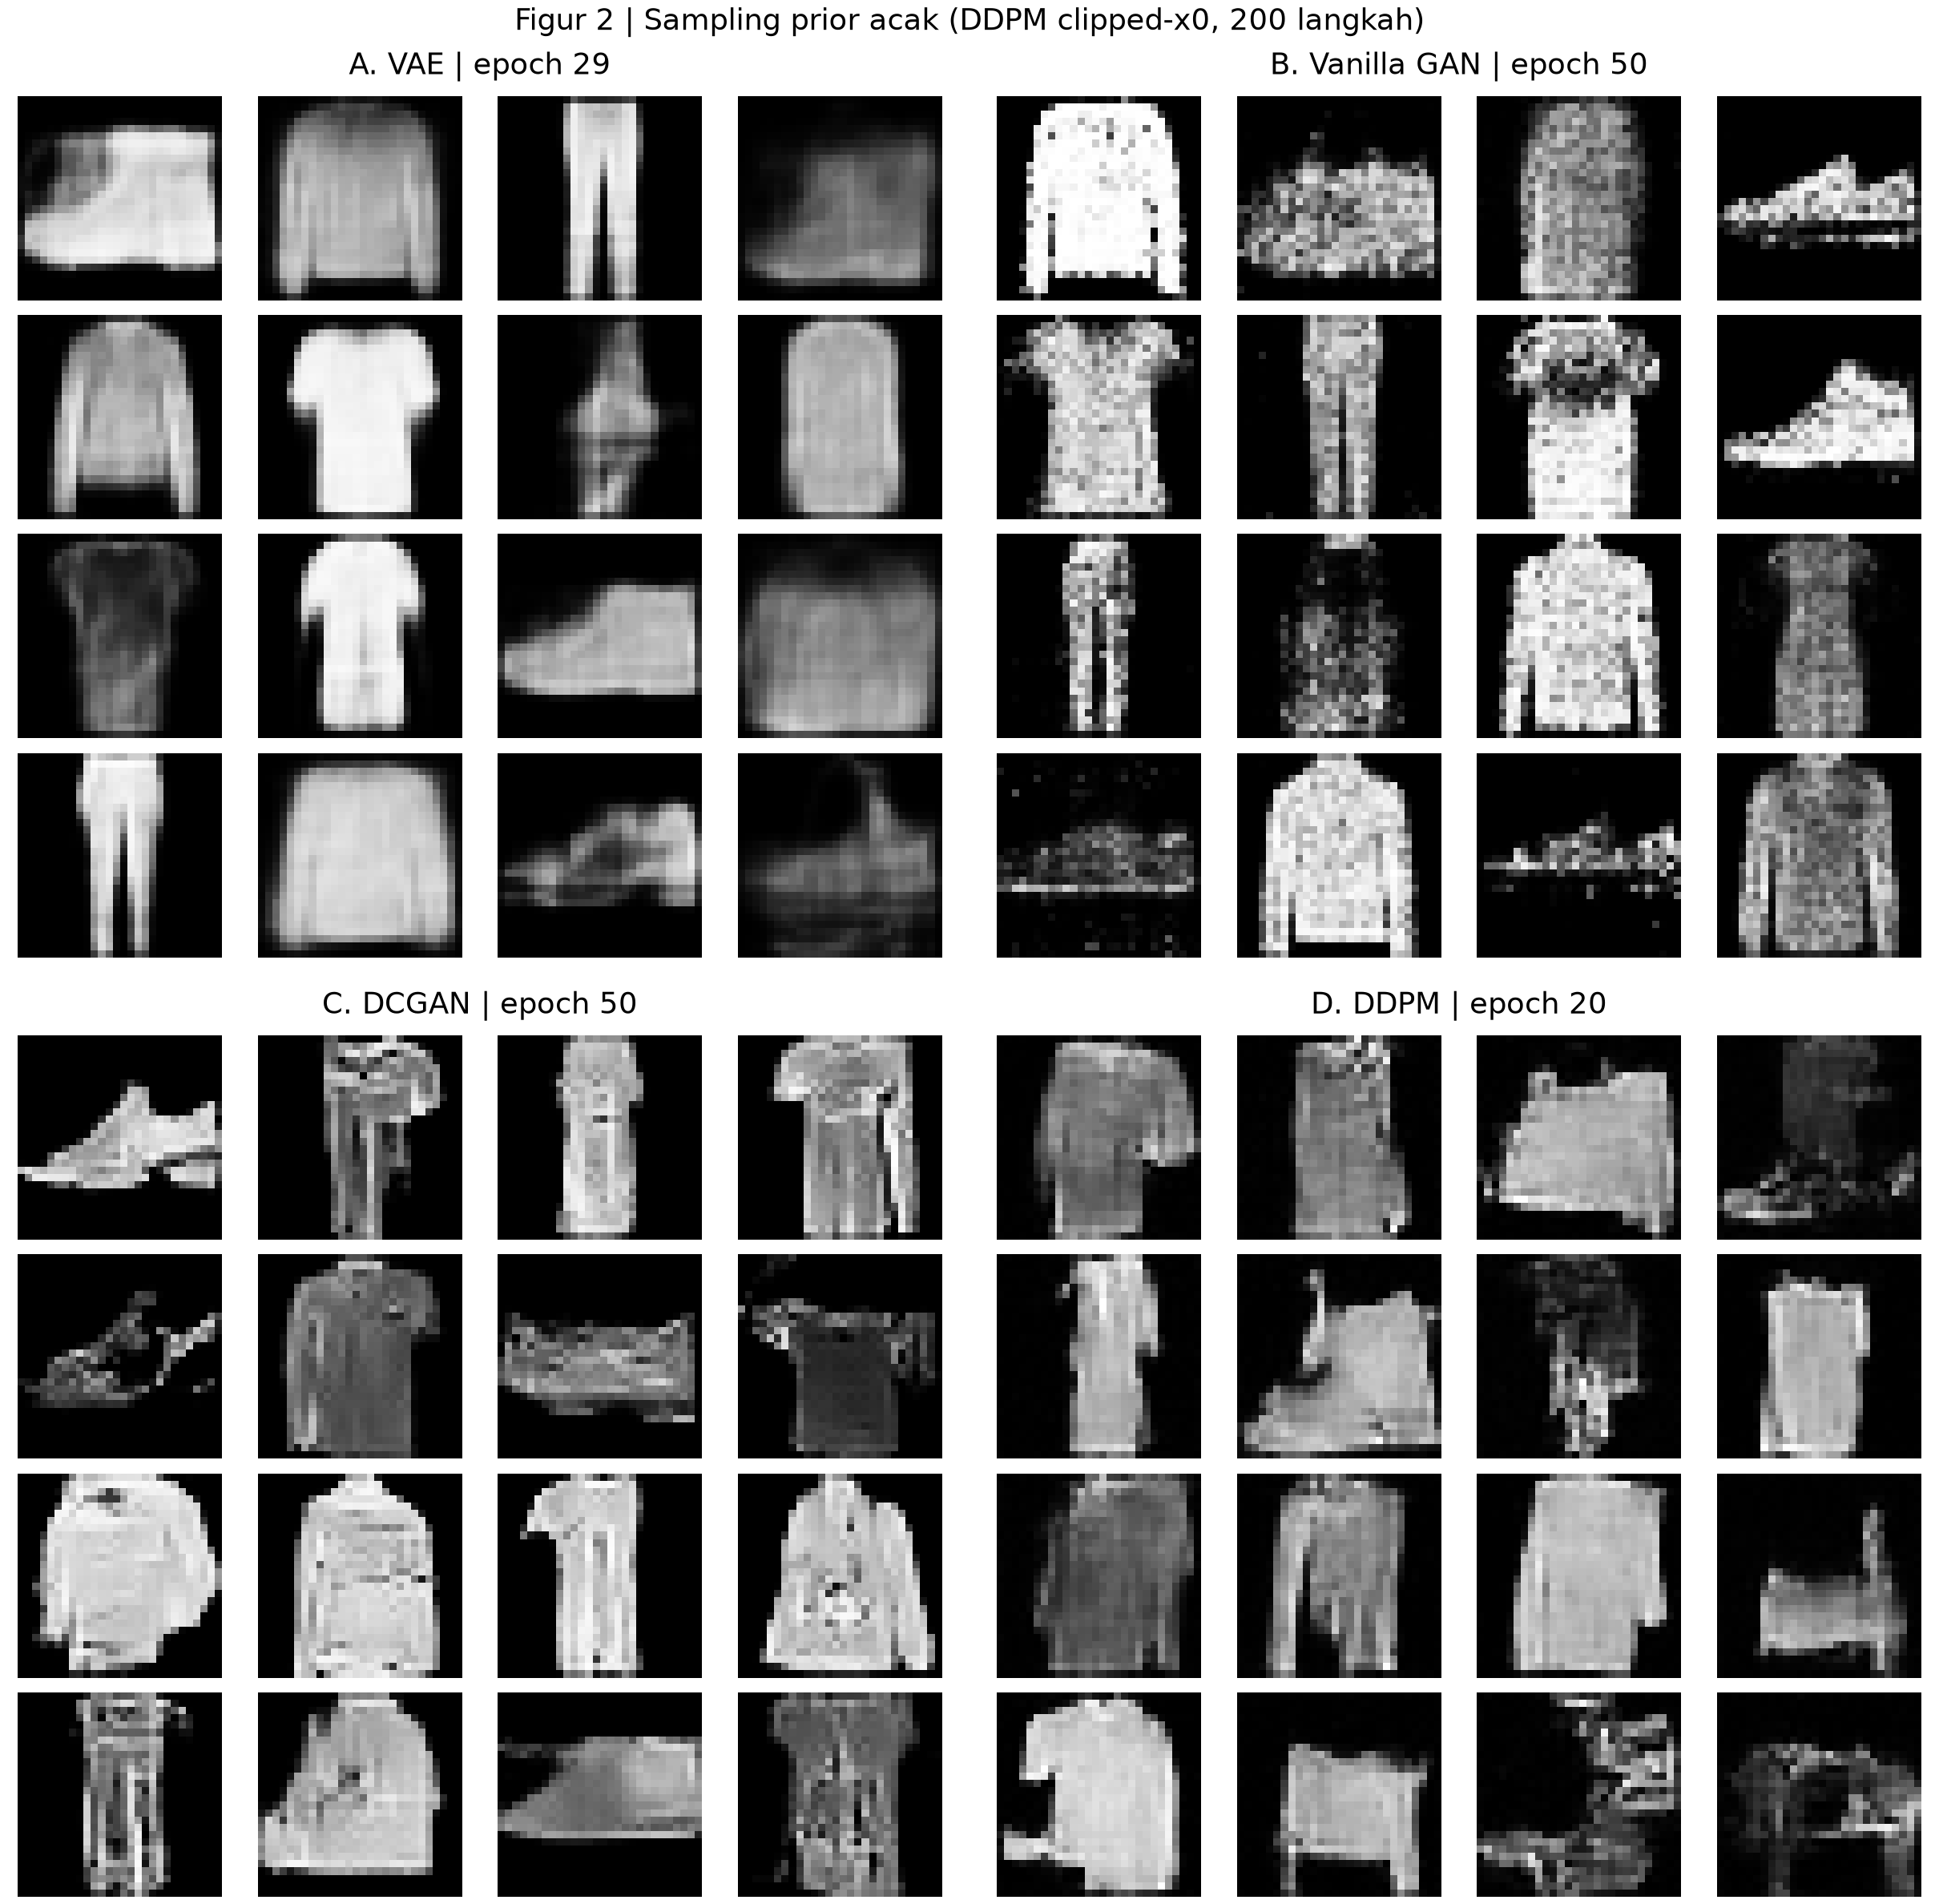

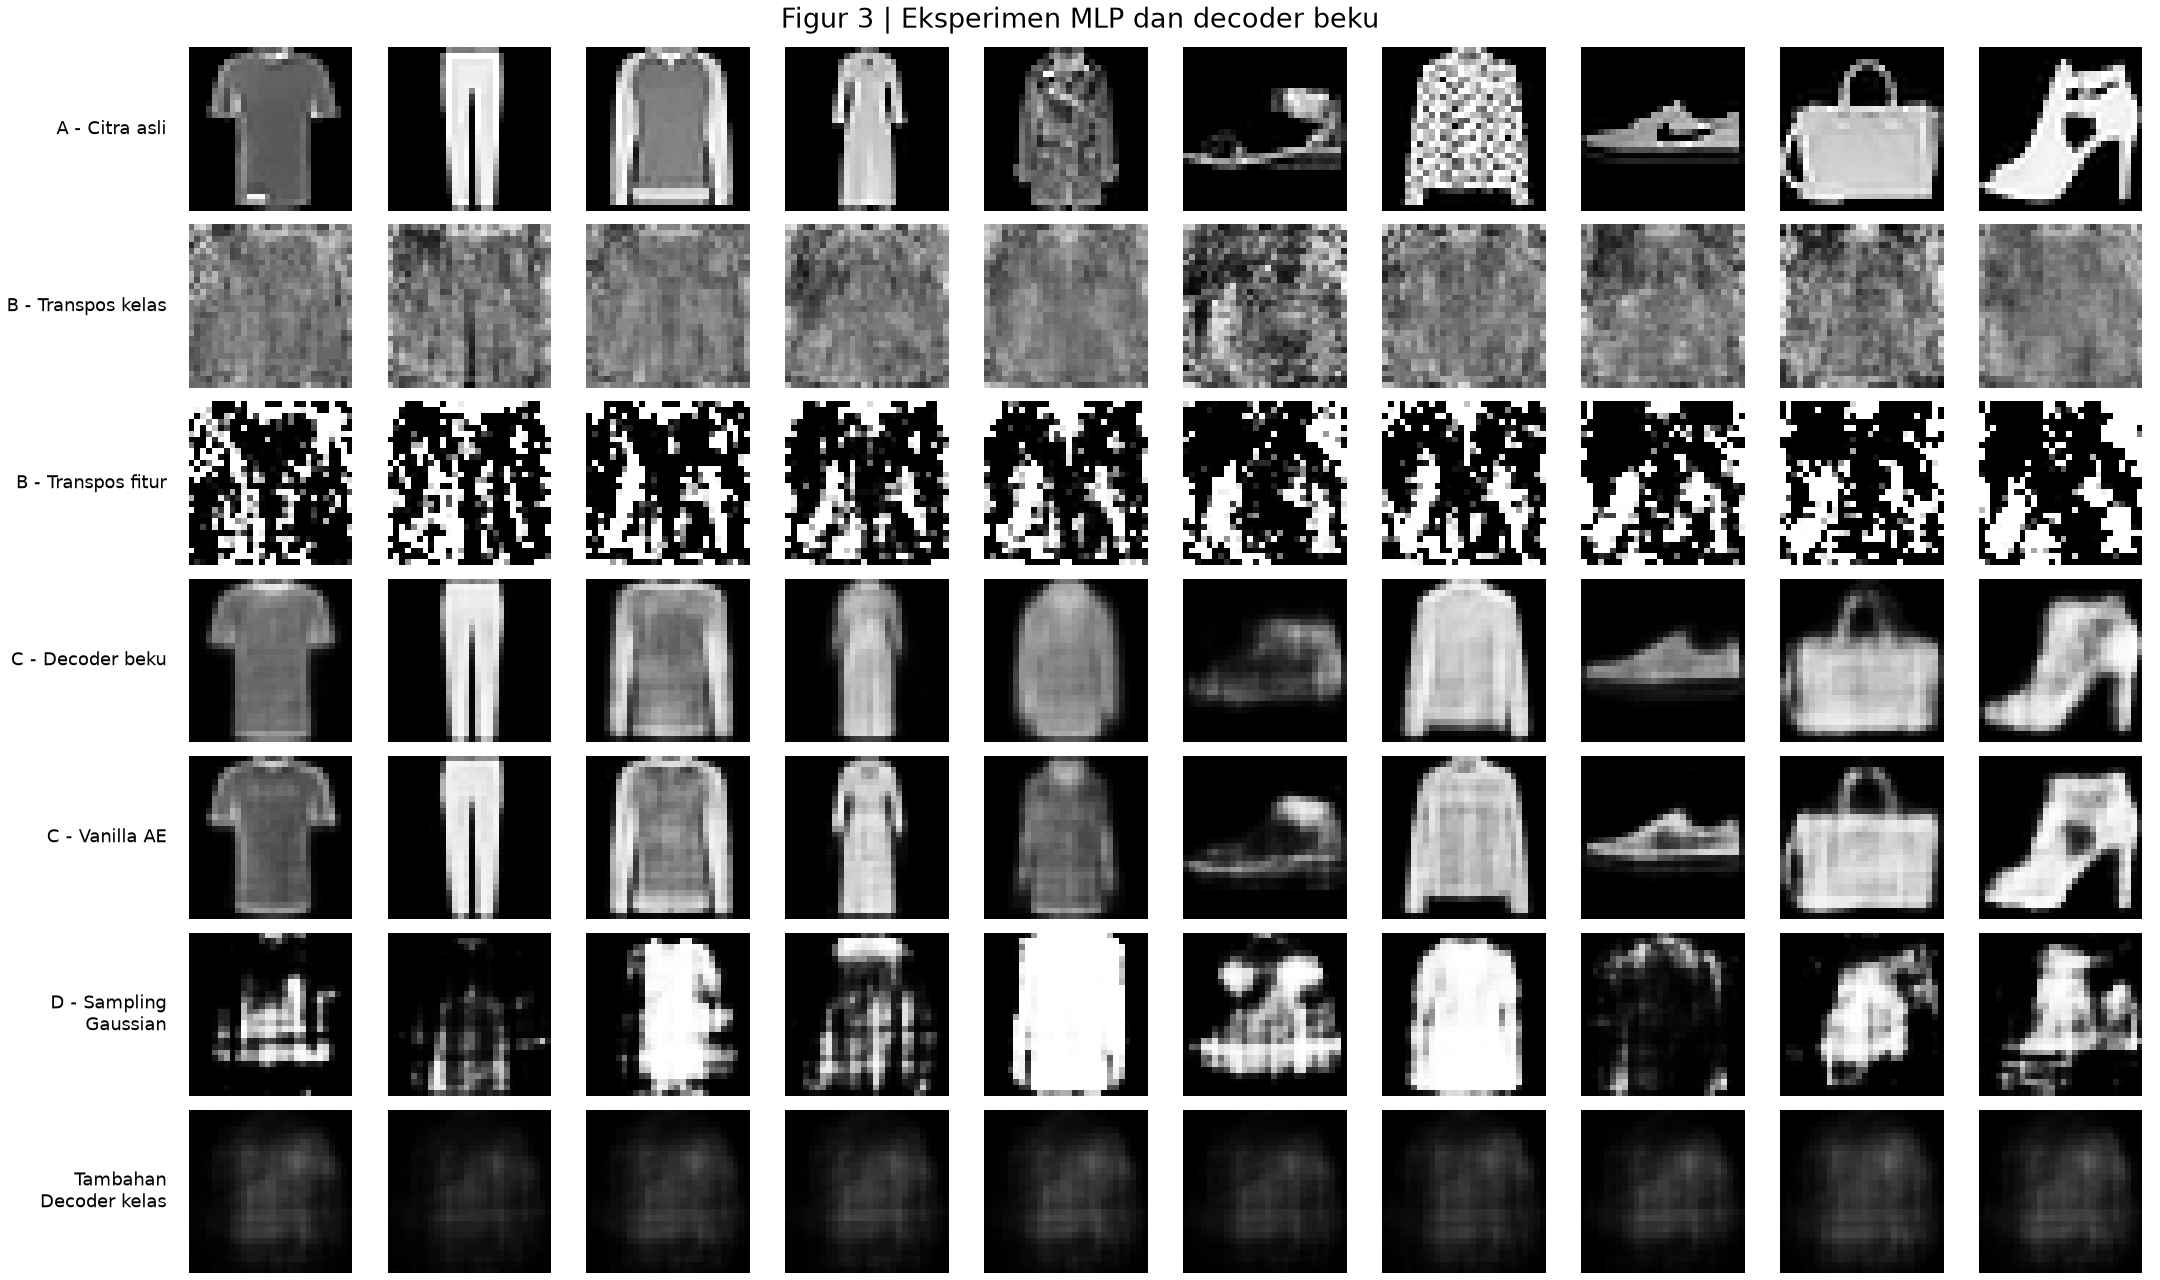

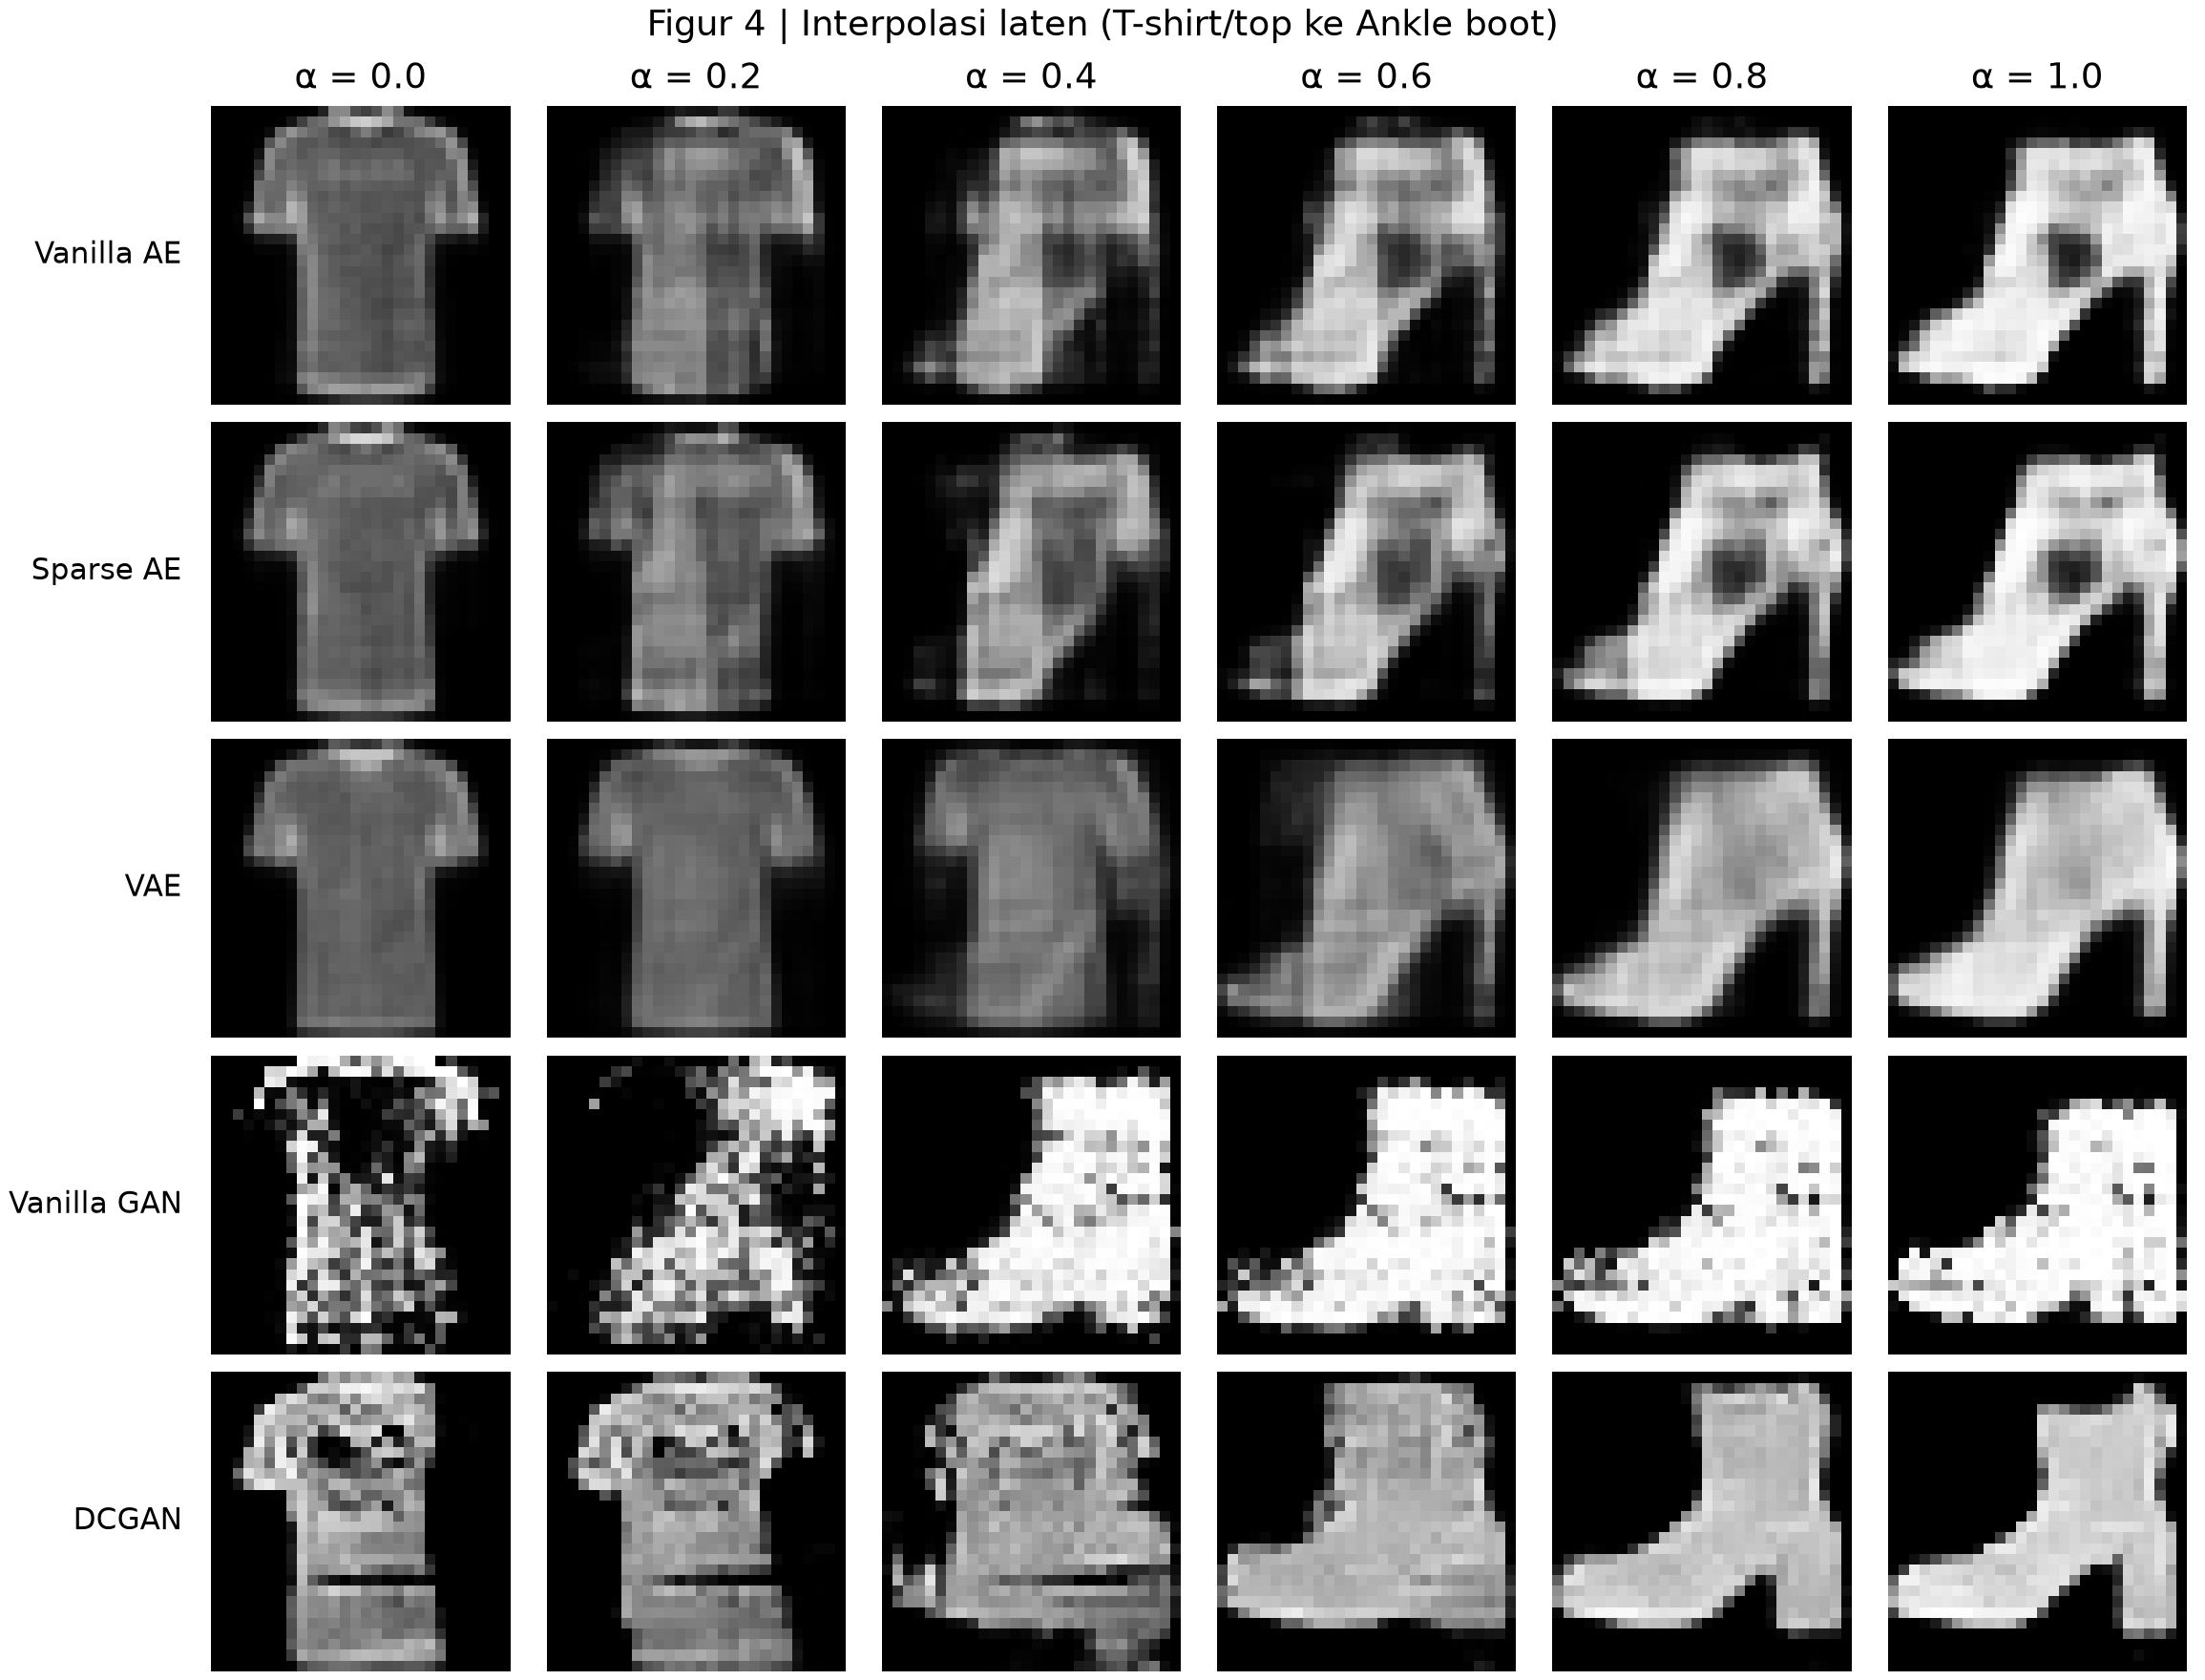

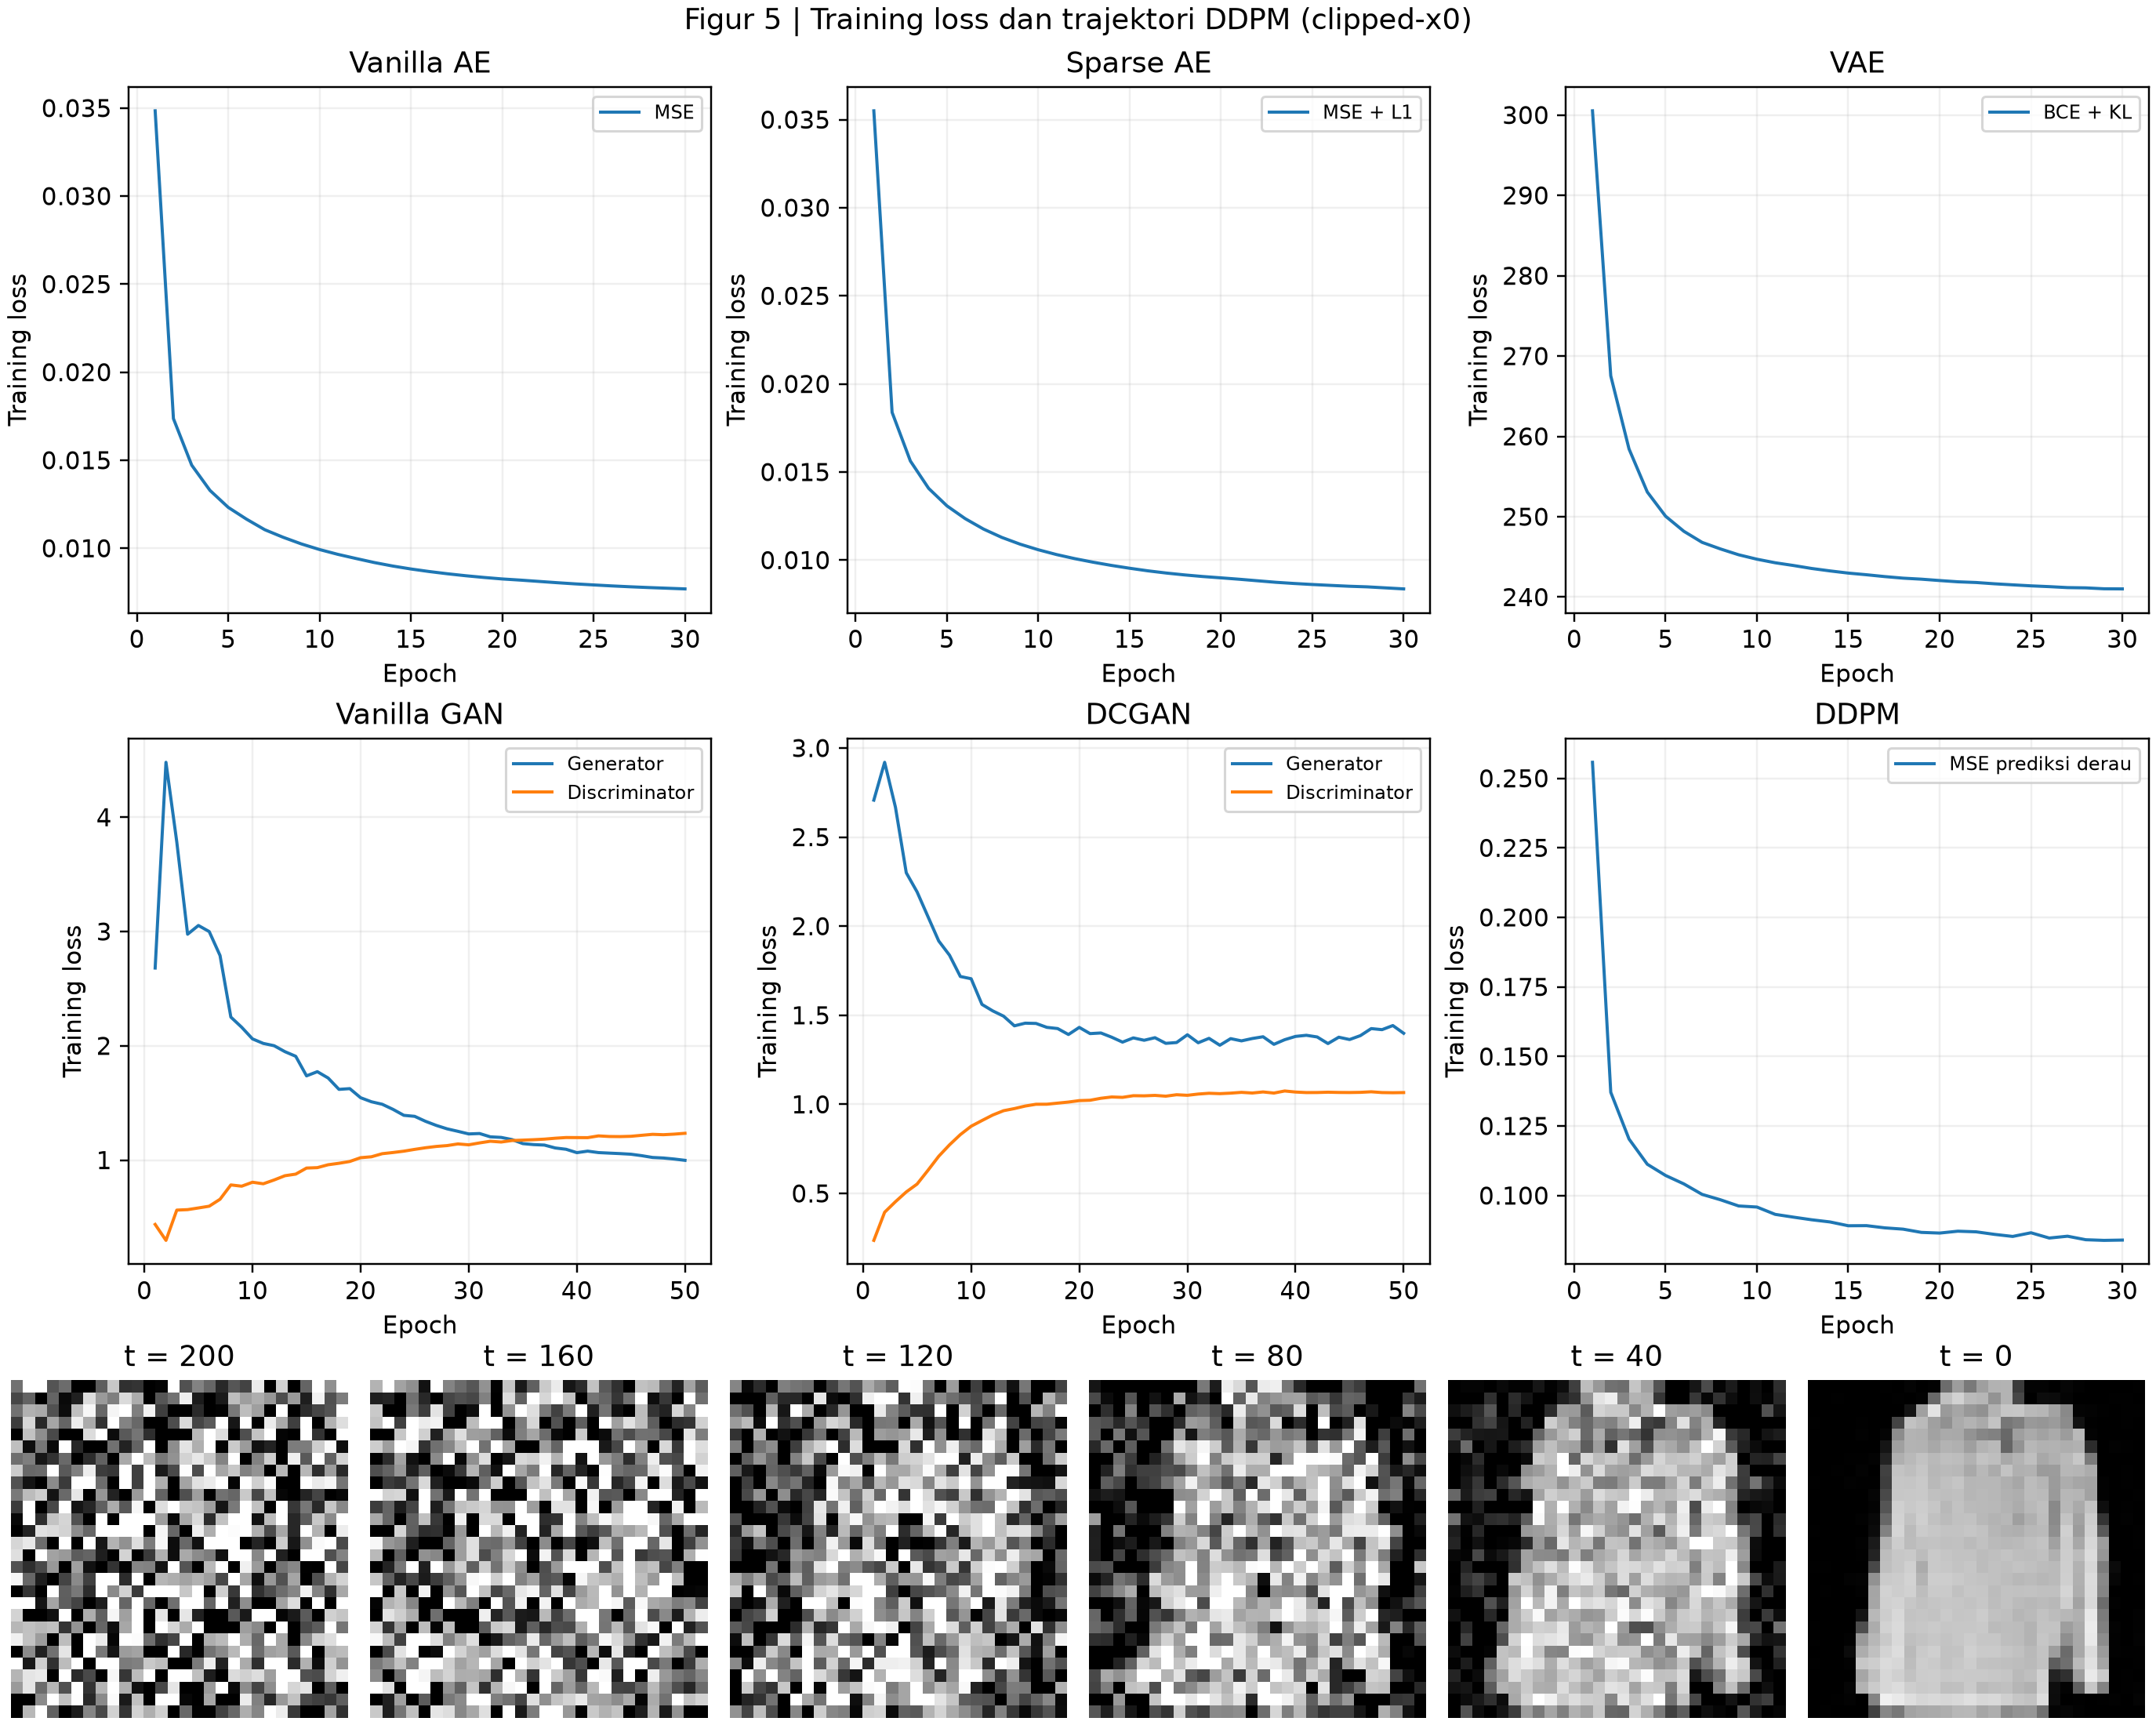

In [3]:
def show_image(ax, data):
    ax.imshow(np.squeeze(data), cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    ax.set(xticks=[], yticks=[])
    for spine in ax.spines.values():
        spine.set_visible(False)


def grid_rows(axs, rows):
    for axes, (label, images) in zip(axs, rows):
        for ax, image in zip(axes, images):
            show_image(ax, image)
        axes[0].set_ylabel(label, rotation=0, ha="right", va="center", labelpad=10)


def save_figure(fig, number, title):
    fig.suptitle(title)
    fig.savefig(FIGURES / f"figure{number}.png", dpi=220, facecolor="white")
    plt.close(fig)


fig, axes = plt.subplots(4, 8, figsize=(12.2, 6), layout="constrained")
grid_rows(axes, [(title, VISUALS[key]) for title, key in (
    ("Citra asli", "original"), ("Vanilla AE", "vanilla_ae_recon"),
    ("Sparse AE", "sparse_ae_recon"), ("VAE", "vae_recon"),
)])
save_figure(fig, 1, "Figur 1 | Rekonstruksi delapan citra Fashion-MNIST dari test set")

fig = plt.figure(figsize=(11, 10.8), layout="constrained")
for panel, (letter, name) in zip(fig.subfigures(2, 2).flat,
                                 zip("ABCD", ("VAE", "Vanilla GAN", "DCGAN", "DDPM"))):
    slug = MODELS[name][0]
    epoch = comparison.loc[comparison["Model"] == name, "Epoch terpilih"].item()
    panel.suptitle(f"{letter}. {name} | epoch {epoch}")
    for ax, image in zip(panel.subplots(4, 4).flat, VISUALS[f"{slug}_samples"]):
        show_image(ax, image)
save_figure(fig, 2, "Figur 2 | Sampling prior acak (DDPM clipped-x0, 200 langkah)")

shutil.copyfile(ROOT / "results/figures/figure3_mlp_decoder.png", FIGURES / "figure3.png")

fig, axes = plt.subplots(5, 6, figsize=(10.5, 8), layout="constrained")
names = ("Vanilla AE", "Sparse AE", "VAE", "Vanilla GAN", "DCGAN")
grid_rows(axes, [(name, VISUALS[f"{MODELS[name][0]}_interp"]) for name in names])
for ax, alpha in zip(axes[0], np.linspace(0, 1, 6)):
    ax.set_title(f"α = {alpha:.1f}")
save_figure(fig, 4, "Figur 4 | Interpolasi laten (T-shirt/top ke Ankle boot)")

fig = plt.figure(figsize=(12.5, 10), layout="constrained")
layout = fig.add_gridspec(3, 3, height_ratios=(1, 1, 0.72))
losses = {
    "Vanilla AE": [("train_loss", "MSE")],
    "Sparse AE": [("train_loss", "MSE + L1")],
    "VAE": [("train_loss", "BCE + KL")],
    "Vanilla GAN": [("g_loss", "Generator"), ("d_loss", "Discriminator")],
    "DCGAN": [("g_loss", "Generator"), ("d_loss", "Discriminator")],
    "DDPM": [("train_mse", "MSE prediksi derau")],
}
for index, (name, series) in enumerate(losses.items()):
    ax = fig.add_subplot(layout[index // 3, index % 3])
    history = HISTORIES[name]
    for column, label in series:
        ax.plot(history["epoch"], history[column], label=label, linewidth=1.3)
    ax.set(title=name, xlabel="Epoch", ylabel="Training loss")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
trajectory = layout[2, :].subgridspec(1, 6)
for index, (step, state) in enumerate(zip(VISUALS["ddpm_steps"], VISUALS["ddpm_trajectory"])):
    ax = fig.add_subplot(trajectory[0, index])
    show_image(ax, state[0])
    ax.set_title(f"t = {step}")
save_figure(fig, 5, "Figur 5 | Training loss dan trajektori DDPM (clipped-x0)")
print("Figur 1–5 tersimpan di", FIGURES)

from IPython.display import Image

for number in range(1, 6):
    display(Image(filename=str(FIGURES / f'figure{number}.png'), width=850))
